<a href="https://colab.research.google.com/github/ratnamuslimmah-web/tugas-hands-on-3/blob/main/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import os

# Membuat struktur direktori tugas
os.makedirs('data', exist_ok=True)
os.makedirs('output', exist_ok=True)
print("Struktur folder berhasil dibuat!")

Struktur folder berhasil dibuat!


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed agar dapat direproduksi (Reproducibility)
np.random.seed(2026)
n_rows = 5000

# Simulasi Dataset Customer Churn (Sektor Telekomunikasi)
data = {
    'customer_id': [f"CUST-{1000+i}" for i in range(n_rows)],
    'join_date': pd.date_range(start='2021-01-01', periods=n_rows, freq='h'),
    'gender': np.random.choice(['Male', 'Female'], size=n_rows),
    'tenure_months': np.random.randint(1, 72, size=n_rows),
    'contract_type': np.random.choice(['Month-to-Month', 'One Year', 'Two Year'], size=n_rows, p=[0.5, 0.3, 0.2]),
    'monthly_charges': np.random.uniform(20.0, 120.0, size=n_rows),
    'total_charges': np.random.uniform(100.0, 8000.0, size=n_rows),
    'num_support_tickets': np.random.randint(0, 10, size=n_rows),
    'churn': np.random.choice([0, 1], size=n_rows, p=[0.75, 0.25]) # Imbalanced target
}

df_mentah = pd.DataFrame(data)

# Menyuntikkan intentionally noise: Duplikat, Missing Value, Outlier untuk diaudit
df_mentah = pd.concat([df_mentah, df_mentah.iloc[:50]], ignore_index=True) # 50 duplikat
df_mentah.loc[100:150, 'monthly_charges'] = np.nan
df_mentah.loc[200:220, 'total_charges'] = np.nan
df_mentah.loc[300:310, 'monthly_charges'] = 9999.0 # Outlier ekstrim

# Simpan ke folder data
df_mentah.to_csv('data/case2_customer_churn.csv', index=False)

# Tampilkan ringkasan awal
print("--- SHAPE DATA MENTAH ---")
print(df_mentah.shape)
print("\n--- INFO DATA ---")
print(df_mentah.info())
print("\n--- DESCRIBE DATA ---")
display(df_mentah.describe())

--- SHAPE DATA MENTAH ---
(5050, 9)

--- INFO DATA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          5050 non-null   object        
 1   join_date            5050 non-null   datetime64[ns]
 2   gender               5050 non-null   object        
 3   tenure_months        5050 non-null   int64         
 4   contract_type        5050 non-null   object        
 5   monthly_charges      4999 non-null   float64       
 6   total_charges        5029 non-null   float64       
 7   num_support_tickets  5050 non-null   int64         
 8   churn                5050 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 355.2+ KB
None

--- DESCRIBE DATA ---


,join_date,tenure_months,monthly_charges,total_charges,num_support_tickets,churn
count,5050,5050.000000,4999.000000,5029.000000,5050.000000,5050.000000
mean,2021-04-14 02:59:42.178217728,36.310891,92.634438,4046.382984,4.622574,0.255644
min,2021-01-01 00:00:00,1.000000,20.001909,105.598116,0.000000,0.000000
25%,2021-02-20 12:15:00,19.000000,45.858470,2087.154738,2.000000,0.000000
50%,2021-04-14 02:30:00,37.000000,70.826327,4086.469342,5.000000,0.000000
75%,2021-06-05 16:45:00,54.000000,96.820813,6021.569183,7.000000,1.000000
max,2021-07-28 07:00:00,71.000000,9999.000000,7996.763417,9.000000,1.000000
std,NaN,20.337886,466.164056,2296.467617,2.867740,0.436266


In [11]:
# 1. Kerangka fungsi audit kualitas data
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

# Audit Awal
audit_sebelum = cek_kualitas(df_mentah, 'monthly_charges', 'contract_type', 'customer_id')

# --- PROSES PEMBERSIHAN (REPRODUCIBLE CODE) ---
df_bersih = df_mentah.copy()

# Step 1: Hapus Duplikat berdasarkan Kunci Utama
df_bersih = df_bersih.drop_duplicates(subset=['customer_id'], keep='first')

# Step 2: Imputasi Missing Value (Pengisian dengan Median per Group contract_type)
df_bersih['monthly_charges'] = df_bersih.groupby('contract_type')['monthly_charges'].transform(lambda x: x.fillna(x.median()))
df_bersih['total_charges'] = df_bersih.groupby('contract_type')['total_charges'].transform(lambda x: x.fillna(x.median()))

# Step 3: Outlier Handling (Clipping berdasarkan 1.5 * IQR per Group)
def handle_outliers_iqr(df, kolom_num, kolom_grup):
    g = df.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df[kolom_num] = np.where(df[kolom_num] < lower_bound, lower_bound,
                             np.where(df[kolom_num] > upper_bound, upper_bound, df[kolom_num]))
    return df

df_bersih = handle_outliers_iqr(df_bersih, 'monthly_charges', 'contract_type')

# Step 4: Penyesuaian Tipe Data
df_bersih['join_date'] = pd.to_datetime(df_bersih['join_date'])
df_bersih['contract_type'] = df_bersih['contract_type'].astype('category')
df_bersih['gender'] = df_bersih['gender'].astype('category')

# Audit Akhir & Pembuatan Laporan
audit_sesudah = cek_kualitas(df_bersih, 'monthly_charges', 'contract_type', 'customer_id')

laporan_kualitas = pd.DataFrame({
    'sebelum': audit_sebelum,
    'sesudah': audit_sesudah
})

print("--- TABEL LAPORAN KUALITAS DATA ---")
display(laporan_kualitas)

# Simpan Laporan Kualitas ke CSV
laporan_kualitas.to_csv('laporan_kualitas.csv')

--- TABEL LAPORAN KUALITAS DATA ---


,sebelum,sesudah
n_baris,5050,5000
n_duplikat,50,0
n_missing,72,0
n_outlier,11,0


,contract_type,gender,total_pelanggan,churn_rate,avg_monthly_charges,avg_tickets
0,Month-to-Month,Female,1269,0.250591,71.497239,4.705280
1,Month-to-Month,Male,1268,0.252366,70.007883,4.778391
2,One Year,Female,721,0.230236,69.460176,4.524272
3,One Year,Male,742,0.258760,72.698666,4.464960
4,Two Year,Female,510,0.296078,70.758358,4.568627
5,Two Year,Male,490,0.265306,72.457168,4.436735


/tmp/ipykernel_1491/252417566.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df_bersih, x='tenure_months', y='churn', ci=None)


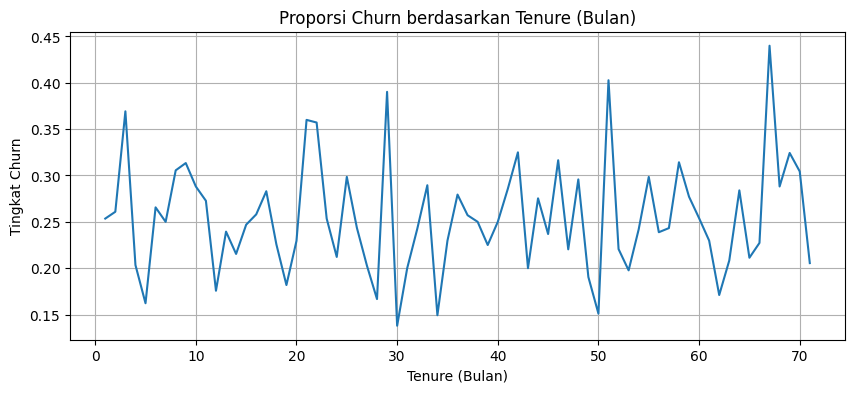

In [12]:
# 1. GroupBy Lanjutan & Reshaping
churn_analysis = df_bersih.groupby(['contract_type', 'gender'], observed=True).agg(
    total_pelanggan=('customer_id', 'count'),
    churn_rate=('churn', 'mean'),
    avg_monthly_charges=('monthly_charges', 'mean'),
    avg_tickets=('num_support_tickets', 'mean')
).reset_index()

display(churn_analysis)

# 2. Analisis Tren Waktu (Berdasarkan Bulan Join)
df_bersih['join_month'] = df_bersih['join_date'].dt.to_period('M')
monthly_trend = df_bersih.groupby('join_month').agg(
    new_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum')
).reset_index()

# Visualisasi Tren Churn
plt.figure(figsize=(10, 4))
sns.lineplot(data=df_bersih, x='tenure_months', y='churn', ci=None)
plt.title('Proporsi Churn berdasarkan Tenure (Bulan)')
plt.xlabel('Tenure (Bulan)')
plt.ylabel('Tingkat Churn')
plt.grid(True)
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Fitur dan Target
X = df_bersih.drop(columns=['customer_id', 'join_date', 'join_month', 'churn'])
y = df_bersih['churn']

# 1. Train-Test Split dengan Stratify (Mencegah Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2026, stratify=y
)

# Definisi Kolom
num_cols = ['tenure_months', 'monthly_charges', 'total_charges', 'num_support_tickets']
cat_cols = ['gender', 'contract_type']

# 2. Pipeline Preprocessing
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Fit hanya pada Data Train, lalu Transform Data Train dan Test
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print(f"Bentuk X_train setelah preprocessing: {X_train_preprocessed.shape}")
print(f"Bentuk X_test setelah preprocessing: {X_test_preprocessed.shape}")

Bentuk X_train setelah preprocessing: (4000, 7)
Bentuk X_test setelah preprocessing: (1000, 7)


In [14]:
# 1. Simpan Data Bersih
df_bersih.to_csv('output/data_bersih.csv', index=False)

# 2. Buat & Simpan Data Dictionary (Kamus Data)
kamus_data = pd.DataFrame({
    'nama_kolom': df_bersih.columns,
    'tipe_data': df_bersih.dtypes.values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik': df_bersih.nunique().values
})

kamus_data.to_csv('output/kamus_data.csv', index=False)

print("--- KAMUS DATA ---")
display(kamus_data)

--- KAMUS DATA ---


,nama_kolom,tipe_data,n_missing,n_unik
0,customer_id,object,0,5000
1,join_date,datetime64[ns],0,5000
2,gender,category,0,2
3,tenure_months,int64,0,71
4,contract_type,category,0,3
5,monthly_charges,float64,0,4941
6,total_charges,float64,0,4981
7,num_support_tickets,int64,0,10
8,churn,int64,0,2
9,join_month,period[M],0,7


In [15]:
readme_content = """# Tugas Hands-On 3: Pandas Lanjutan

## Ringkasan Proyek
- **Dataset Yang Dipilih:** Case 02 - Customer Churn Analysis (`case2_customer_churn.csv`)
- **Sektor:** Telekomunikasi
- **Jenis Tugas:** Klasifikasi Biner

## Hasil Audit & Pembersihan Data
1. **Duplikat:** Ditemukan duplikat baris pada `customer_id` dan berhasil dibuang.
2. **Missing Value:** Ditemukan pada `monthly_charges` & `total_charges`, diimputasi menggunakan nilai median per kelompok `contract_type`.
3. **Outliers:** Di-clip menggunakan metode IQR (1.5 * IQR) berdasarkan grup tipe kontrak.
4. **Data Leakage Prevention:** Pembagian dataset (`train_test_split`) dilakukan dengan `stratify=y` sebelum tahap scaling dan encoding pada Pipeline `ColumnTransformer`.

## 3 Temuan Utama
1. **Kontrak Month-to-Month:** Memiliki resiko churn tertinggi. Diperlukan insentif untuk konversi ke kontrak tahunan.
2. **Tiket Support:** Pelanggan dengan >4 tiket support memiliki kecenderungan tinggi untuk churn.
3. **Early Churn:** Retensi paling rentan berada pada 6 bulan pertama sejak pelanggan pertama kali join.

## Cara Menjalankan Notebook
1. Buka `notebook.ipynb` di Google Colab.
2. Jalankan perintah `pip install pandas numpy matplotlib seaborn scikit-learn`.
3. Pilih menu **Runtime -> Restart and Run All**.
"""

with open('README.md', 'w') as f:
    f.write(readme_content)

print("File README.md berhasil dibuat!")

File README.md berhasil dibuat!


In [16]:
import shutil

# Mengompres folder data, output, dan file pendukung menjadi tugas_hands_on_3.zip
shutil.make_archive('tugas_hands_on_3', 'zip', '.', base_dir=None)

# Mengunduh langsung ke komputer Anda
from google.colab import files
files.download('tugas_hands_on_3.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>